# BTL01 – Xấp xỉ hàm Gaussian 2 chiều bằng MLP (PyTorch)
**Học sâu – Bài tập xấp xỉ hàm số dùng MLP** 




##  Cấu hình chung

In [2]:
import json, time, copy, types
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# ---- Cấu hình ----
QUICK  = False                 # True: chạy thử nhanh (30 epoch, 1 seed)
SEEDS  = [0] if QUICK else [0, 1, 2, 3, 4]   # seed khởi tạo + thứ tự batch -> báo cáo TB ± std
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"   # GPU là tuỳ chọn, CPU vẫn chạy tốt
ROOT = Path.cwd()              # notebook đặt ở thư mục gốc dự án; không phụ thuộc đường dẫn cá nhân
DATA_DIR, RES_DIR, FIG_DIR = ROOT / "data", ROOT / "results", ROOT / "figures"
for p in (DATA_DIR, RES_DIR, RES_DIR / "logs", FIG_DIR, ROOT / "models"):
    p.mkdir(parents=True, exist_ok=True)
print("PyTorch", torch.__version__, "| device:", DEVICE, "| QUICK =", QUICK, "| seeds:", SEEDS)

PyTorch 2.10.0+cpu | device: cpu | QUICK = False | seeds: [0, 1, 2, 3, 4]


## 1. Dữ liệu
- Hàm `gaussian_pdf` viết **trực tiếp theo công thức** (không gọi `scipy.stats`); đã đối chiếu với `scipy.stats.multivariate_normal` (sai khác tối đa ≈ 1e-16).
- `x₁ ~ U(−2,2)`, `x₂ ~ U(−4,4)`; nhãn `y = f(x)`. **Train (pool 2000) / validation (200) / test (100)** lấy từ 3 luồng RNG độc lập (`SeedSequence(2026).spawn(3)`) → không trùng, không rò rỉ. Nhóm A lấy *A mẫu đầu* của pool (tập con lồng nhau) để so sánh công bằng.
- Đầu vào chuẩn hoá theo **miền cố định** (`x₁/2`, `x₂/4`), không dùng thống kê của val/test.

In [3]:
"""Hằng số + hàm dùng chung (không phụ thuộc PyTorch)."""
import numpy as np

ACTS = {
    "tanh": np.tanh,
    "relu": lambda z: np.maximum(z, 0.0),
    "sigmoid": lambda z: 1.0 / (1.0 + np.exp(-z)),
}


def numpy_forward(state, X, activation="tanh"):
    """Forward bằng NumPy từ state {W0,b0,W1,b1,...}; W có shape (out,in) như nn.Linear.
    Dùng để vẽ bề mặt xấp xỉ độc lập với engine huấn luyện."""
    n_layers = len([k for k in state if k.startswith("W")])
    a = np.asarray(X, dtype=np.float64)
    act = ACTS[activation]
    for i in range(n_layers):
        a = a @ np.asarray(state[f"W{i}"], dtype=np.float64).T + np.asarray(state[f"b{i}"], dtype=np.float64)
        if i < n_layers - 1:
            a = act(a)
    return a.reshape(-1)


def regression_metrics(y_true, y_pred):
    e = np.asarray(y_pred, dtype=np.float64).reshape(-1) - np.asarray(y_true, dtype=np.float64).reshape(-1)
    mse = float(np.mean(e ** 2))
    return {"mse": mse, "mae": float(np.mean(np.abs(e))), "rmse": float(np.sqrt(mse))}

In [4]:

from pathlib import Path
import numpy as np
import pandas as pd

MU = np.array([0.0, 0.0])
COV = np.array([[0.3, -0.5], [-0.5, 2.0]])
X1_RANGE = (-2.0, 2.0)
X2_RANGE = (-4.0, 4.0)
DATA_SEED = 2026
N_POOL, N_VAL, N_TEST = 2000, 200, 100
SCALE = np.array([2.0, 4.0])  # chuẩn hoá theo miền: x / SCALE ∈ [-1,1] (không dùng thống kê test -> không rò rỉ)


def gaussian_pdf(x, mu=MU, cov=COV):
    """Gaussian nhiều chiều viết trực tiếp theo công thức đề bài."""
    x = np.atleast_2d(np.asarray(x, dtype=np.float64))
    d = x.shape[1]
    diff = x - mu
    maha = np.einsum("ni,ij,nj->n", diff, np.linalg.inv(cov), diff)
    return np.exp(-0.5 * maha) / (((2 * np.pi) ** (d / 2)) * np.sqrt(np.linalg.det(cov)))


def sample_x(n, rng):
    x1 = rng.uniform(*X1_RANGE, size=n)
    x2 = rng.uniform(*X2_RANGE, size=n)
    return np.stack([x1, x2], axis=1)


def generate_splits(seed=DATA_SEED, n_pool=N_POOL, n_val=N_VAL, n_test=N_TEST):
    streams = [np.random.default_rng(s) for s in np.random.SeedSequence(seed).spawn(3)]
    out = {}
    for name, n, rng in zip(["train", "val", "test"], [n_pool, n_val, n_test], streams):
        x = sample_x(n, rng)
        out[name] = pd.DataFrame({"x1": x[:, 0], "x2": x[:, 1], "y": gaussian_pdf(x)})
    return out


def save_splits(splits, data_dir):
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    for k, df in splits.items():
        df.to_csv(data_dir / f"{k}.csv", index=False)


def load_splits(data_dir):
    """Nạp CSV nếu có; nếu chưa có thì sinh (cùng seed) và lưu."""
    data_dir = Path(data_dir)
    if not all((data_dir / f"{k}.csv").exists() for k in ["train", "val", "test"]):
        save_splits(generate_splits(), data_dir)
    return {k: pd.read_csv(data_dir / f"{k}.csv") for k in ["train", "val", "test"]}


def to_arrays(df, n=None):
    """DataFrame -> (X chuẩn hoá, y). n: lấy n mẫu đầu."""
    if n is not None:
        df = df.iloc[:n]
    X = df[["x1", "x2"]].to_numpy(dtype=np.float64) / SCALE
    return X, df["y"].to_numpy(dtype=np.float64)


def describe(splits):
    rows = []
    for k, df in splits.items():
        for c in ["x1", "x2", "y"]:
            s = df[c]
            rows.append(dict(split=k, var=c, n=len(s), mean=s.mean(), std=s.std(), min=s.min(), max=s.max()))
    return pd.DataFrame(rows)

### Hàm vẽ hình

In [5]:
"""Vẽ hình cho báo cáo (matplotlib, backend Agg)."""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 160, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10, "axes.titlesize": 11})
COL = {"train": "#2a9d8f", "val": "#e9a23b", "test": "#d1495b"}


def _save(fig, path):
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    display(Image(filename=str(path)))   # hiển thị trong notebook
    plt.close(fig)


def _grid(n=70):
    g1 = np.linspace(*X1_RANGE, n)
    g2 = np.linspace(*X2_RANGE, n)
    G1, G2 = np.meshgrid(g1, g2)
    return G1, G2, np.stack([G1.ravel(), G2.ravel()], 1)


def fig_data(splits, fig_dir):
    fig = plt.figure(figsize=(14, 4.4))
    for i, (k, c, t) in enumerate([("train", COL["train"], "Train (pool 2000 mẫu)"),
                                   ("val", COL["val"], "Validation (200 mẫu)"),
                                   ("test", COL["test"], "Test (100 mẫu)")]):
        ax = fig.add_subplot(1, 3, i + 1, projection="3d")
        df = splits[k]
        ax.scatter(df.x1, df.x2, df.y, s=6 if k == "train" else 14, c=c, alpha=0.7)
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$y=f(x)$"); ax.set_title(t)
        ax.view_init(25, -55)
    _save(fig, Path(fig_dir) / "fig01_data_scatter3d.png")

    G1, G2, P = _grid()
    Z = gaussian_pdf(P).reshape(G1.shape)
    fig = plt.figure(figsize=(11, 4.6))
    ax = fig.add_subplot(1, 2, 1, projection="3d")
    ax.plot_surface(G1, G2, Z, cmap="viridis", linewidth=0, antialiased=True)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$f(x)$"); ax.set_title("Bề mặt hàm Gaussian thật")
    ax.view_init(28, -55)
    ax = fig.add_subplot(1, 2, 2)
    cs = ax.contourf(G1, G2, Z, 20, cmap="viridis")
    fig.colorbar(cs, ax=ax, label="$f(x)$")
    tr = splits["train"]
    ax.scatter(tr.x1[:500], tr.x2[:500], s=3, c="white", alpha=0.6, label="500 mẫu train đầu")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title("Đường đồng mức và mẫu train"); ax.legend(loc="upper right")
    _save(fig, Path(fig_dir) / "fig02_true_surface.png")

    fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
    for ax, c, t in zip(axs, ["x1", "x2", "y"], ["$x_1$", "$x_2$", "$y$"]):
        for k in ["train", "val", "test"]:
            ax.hist(splits[k][c], bins=30, alpha=0.45, density=True, color=COL[k], label=k)
        ax.set_xlabel(t); ax.set_ylabel("mật độ"); ax.set_title(f"Phân bố {t}")
        if c == "y":
            ax.set_yscale("log")
    axs[0].legend()
    _save(fig, Path(fig_dir) / "fig03_distributions.png")


def _band(ax, df, x, col, label, color, marker="o"):
    m, s = df[f"{col}_mean"].to_numpy(), df[f"{col}_std"].fillna(0).to_numpy()
    lo = np.minimum(s, 0.8 * m)          # tránh thanh sai số xuống ≤ 0 trên thang log (cắt tại 20% giá trị TB)
    ax.errorbar(x, m, yerr=[lo, s], marker=marker, ms=4, capsize=3, color=color, label=label)


def fig_sweep(summ, xcol, xlabel, path, title, logx=False, mae=True):
    x = summ[xcol].to_numpy()
    ncol = 2 if mae else 1
    fig, axs = plt.subplots(1, ncol, figsize=(11 if mae else 6, 4))
    axs = np.atleast_1d(axs)
    for k in ["train", "val", "test"]:
        _band(axs[0], summ, x, f"{k}_mse", k, COL[k])
    axs[0].set_yscale("log"); axs[0].set_xlabel(xlabel); axs[0].set_ylabel("MSE (thang log)")
    axs[0].set_title(f"{title}: MSE (trung bình ± độ lệch chuẩn)"); axs[0].legend()
    if mae:
        for k in ["train", "val", "test"]:
            _band(axs[1], summ, x, f"{k}_mae", k, COL[k])
        axs[1].set_yscale("log"); axs[1].set_xlabel(xlabel); axs[1].set_ylabel("MAE (thang log)")
        axs[1].set_title(f"{title}: MAE"); axs[1].legend()
    if logx:
        for a in axs:
            a.set_xscale("log")
    _save(fig, path)


def fig_A_compare(sA, sA2, path):
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    for s, lab, c in [(sA, "Cố định 1000 epoch", "#264653"), (sA2, "Cân bằng số bước cập nhật", "#e76f51")]:
        _band(axs[0], s, s.A, "test_mse", lab, c)
        gap = s.copy()
        axs[1].plot(s.A, s.test_mse_mean / s.train_mse_mean, marker="o", color=c, label=lab)
    axs[0].set_yscale("log"); axs[0].set_xlabel("Số mẫu huấn luyện A"); axs[0].set_ylabel("Test MSE")
    axs[0].set_title("Test MSE theo A: hai cách đặt ngân sách huấn luyện"); axs[0].legend()
    axs[1].set_xlabel("Số mẫu huấn luyện A"); axs[1].set_ylabel("Test MSE / Train MSE")
    axs[1].set_title("Tỉ số test/train (khoảng cách tổng quát hoá)"); axs[1].axhline(1, color="gray", ls="--"); axs[1].legend()
    _save(fig, path)


def _mean_curve(logs_dir, exp, tag, seeds, col):
    curves = [pd.read_csv(Path(logs_dir) / f"{exp}_{tag}_s{s}.csv")[col].to_numpy() for s in seeds]
    L = min(len(c) for c in curves)
    return np.mean([c[:L] for c in curves], 0)


def fig_C(sC, logs_dir, seeds, path):
    fig, axs = plt.subplots(1, 3, figsize=(15, 4))
    x = sC.C.to_numpy()
    for k in ["train", "val", "test"]:
        _band(axs[0], sC, x, f"{k}_mse", k, COL[k])
    axs[0].set_yscale("log"); axs[0].set_xlabel("Số tầng ẩn C (10 nơ-ron/tầng)"); axs[0].set_ylabel("MSE (thang log)")
    axs[0].set_title("MSE theo độ sâu"); axs[0].legend(); axs[0].set_xticks(x)
    cm = plt.cm.viridis(np.linspace(0, 0.9, len(sC)))
    for c, (_, r) in zip(cm, sC.iterrows()):
        axs[1].plot(_mean_curve(logs_dir, "C", r.tag, seeds, "val_loss"), color=c, label=f"C={int(r.C)}")
    axs[1].set_yscale("log"); axs[1].set_xscale("log"); axs[1].set_xlabel("Epoch"); axs[1].set_ylabel("Validation loss (MSE)")
    axs[1].set_title("Hội tụ của validation loss (TB các seed)"); axs[1].legend()
    _band(axs[2], sC, x, "train_time_s", "tổng thời gian (s)", "#6a4c93")
    axs[2].set_xlabel("Số tầng ẩn C"); axs[2].set_ylabel("Tổng thời gian huấn luyện (giây)"); axs[2].set_xticks(x)
    ax2 = axs[2].twinx(); ax2.grid(False)
    _band(ax2, sC, x, "ms_per_epoch", "ms / epoch", "#2a9d8f", marker="s")
    ax2.set_ylabel("Thời gian mỗi epoch (ms)")
    h1, l1 = axs[2].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    axs[2].legend(h1 + h2, l1 + l2, loc="upper left")
    axs[2].set_title("Thời gian huấn luyện (CPU)")
    _save(fig, path)


def fig_curves(logs_dir, path, items):
    fig, axs = plt.subplots(1, len(items), figsize=(5.5 * len(items), 4), squeeze=False)
    for ax, (exp, tag, title) in zip(axs[0], items):
        d = pd.read_csv(Path(logs_dir) / f"{exp}_{tag}_s0.csv")
        ax.plot(d.epoch, d.train_loss, color=COL["train"], label="train")
        ax.plot(d.epoch, d.val_loss, color=COL["val"], label="validation")
        b = d.val_loss.idxmin()
        ax.scatter([d.epoch[b]], [d.val_loss[b]], c="k", zorder=5, label=f"checkpoint (epoch {int(d.epoch[b])})")
        ax.set_yscale("log"); ax.set_xlabel("Epoch"); ax.set_ylabel("MSE"); ax.set_title(title); ax.legend()
    _save(fig, path)


def fig_final(state, activation, splits, metrics, fig_dir, title_tag):
    te = splits["test"]
    X, y = to_arrays(te)
    yh = numpy_forward(state, X, activation)
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
    axs[0].scatter(y, yh, s=18, c=COL["test"], alpha=0.8)
    lim = [0, max(y.max(), yh.max()) * 1.05]
    axs[0].plot(lim, lim, "k--", lw=1, label="$\\hat y = y$")
    axs[0].set_xlabel("y thật"); axs[0].set_ylabel("$\\hat y$ dự đoán"); axs[0].legend()
    axs[0].set_title(f"Tập test (100 mẫu): MSE={metrics['mse']:.2e}, MAE={metrics['mae']:.2e}")
    err = yh - y
    axs[1].scatter(y, err, s=18, c=COL["val"], alpha=0.8); axs[1].axhline(0, color="k", lw=1)
    axs[1].set_xlabel("y thật"); axs[1].set_ylabel("sai số $\\hat y - y$"); axs[1].set_title("Sai số theo giá trị y")
    _save(fig, Path(fig_dir) / "fig11_final_y_vs_yhat.png")

    G1, G2, P = _grid()
    Z = gaussian_pdf(P).reshape(G1.shape)
    Zh = numpy_forward(state, P / SCALE, activation).reshape(G1.shape)
    fig = plt.figure(figsize=(15, 4.6))
    ax = fig.add_subplot(1, 3, 1, projection="3d")
    ax.plot_surface(G1, G2, Z, cmap="viridis", linewidth=0, alpha=0.85)
    ax.set_title("Hàm thật $f(x)$"); ax.view_init(28, -55)
    ax = fig.add_subplot(1, 3, 2, projection="3d")
    ax.plot_surface(G1, G2, Zh, cmap="plasma", linewidth=0, alpha=0.85)
    ax.scatter(te.x1, te.x2, te.y, c="k", s=8, label="test (y thật)")
    ax.set_title("Bề mặt MLP xấp xỉ $\\hat f(x)$"); ax.view_init(28, -55); ax.legend(loc="upper left")
    for a in fig.axes:
        a.set_xlabel("$x_1$"); a.set_ylabel("$x_2$")
    ax = fig.add_subplot(1, 3, 3)
    E = np.abs(Zh - Z)
    cs = ax.contourf(G1, G2, E, 20, cmap="magma")
    fig.colorbar(cs, ax=ax, label="$|\\hat f - f|$")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title(f"Sai số tuyệt đối trên lưới ({title_tag})")
    _save(fig, Path(fig_dir) / "fig12_final_surface.png")
    return dict(max_abs_err=float(E.max()), mean_abs_err=float(E.mean()))


def fig_arch(fig_dir):
    """Sơ đồ kiến trúc: (a) 2-B-1 một tầng ẩn, (b) C tầng ẩn."""
    def draw(ax, sizes, labels, title):
        xs = np.linspace(0, 1, len(sizes))
        pos = []
        for x, n in zip(xs, sizes):
            ys = np.linspace(0.12, 0.88, n) if n > 1 else [0.5]
            pos.append([(x, y) for y in ys])
        for L in range(len(sizes) - 1):
            for p in pos[L]:
                for q in pos[L + 1]:
                    ax.plot([p[0], q[0]], [p[1], q[1]], color="#999", lw=0.5, zorder=1)
        for L, pts in enumerate(pos):
            c = "#4c78a8" if L == 0 else ("#d1495b" if L == len(sizes) - 1 else "#f2a541")
            for p in pts:
                ax.scatter(*p, s=260, c=c, edgecolor="k", zorder=2)
            ax.text(xs[L], 0.0, labels[L], ha="center", va="top", fontsize=9)
        ax.set_xlim(-0.12, 1.12); ax.set_ylim(-0.2, 1.0); ax.axis("off"); ax.set_title(title)
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
    draw(axs[0], [2, 5, 1], ["đầu vào\n$(x_1,x_2)$", "tầng ẩn\n(B nơ-ron, tanh)", "đầu ra $\\hat y$\n(tuyến tính)"],
         "(a) MLP 1 tầng ẩn: 2 - B - 1 (minh hoạ B=5)")
    draw(axs[1], [2, 4, 4, 4, 1], ["đầu vào", "ẩn 1", "ẩn 2", "ẩn C", "đầu ra"],
         "(b) MLP C tầng ẩn (minh hoạ C=3, 4 nơ-ron/tầng)")
    for a in axs:
        a.grid(False)
    _save(fig, Path(fig_dir) / "fig10_architecture.png")

### 1.1 Sinh, lưu, khảo sát và trực quan hoá dữ liệu

,split,var,n,mean,std,min,max
0,train,x1,2000,-0.0020,1.1599,-1.9955,1.9944
1,train,x2,2000,0.0152,2.3381,-3.9991,3.9943
2,train,y,2000,0.0296,0.0553,0.0000,0.2667
3,val,x1,200,0.0866,1.1404,-1.9983,1.9803
4,val,x2,200,-0.0738,2.3358,-3.9861,3.9474
5,val,y,200,0.0307,0.0551,0.0000,0.2650
6,test,x1,100,-0.1047,1.1376,-1.9943,1.8674
7,test,x2,100,-0.1488,2.2546,-3.5826,3.9618
8,test,y,100,0.0320,0.0588,0.0000,0.2649


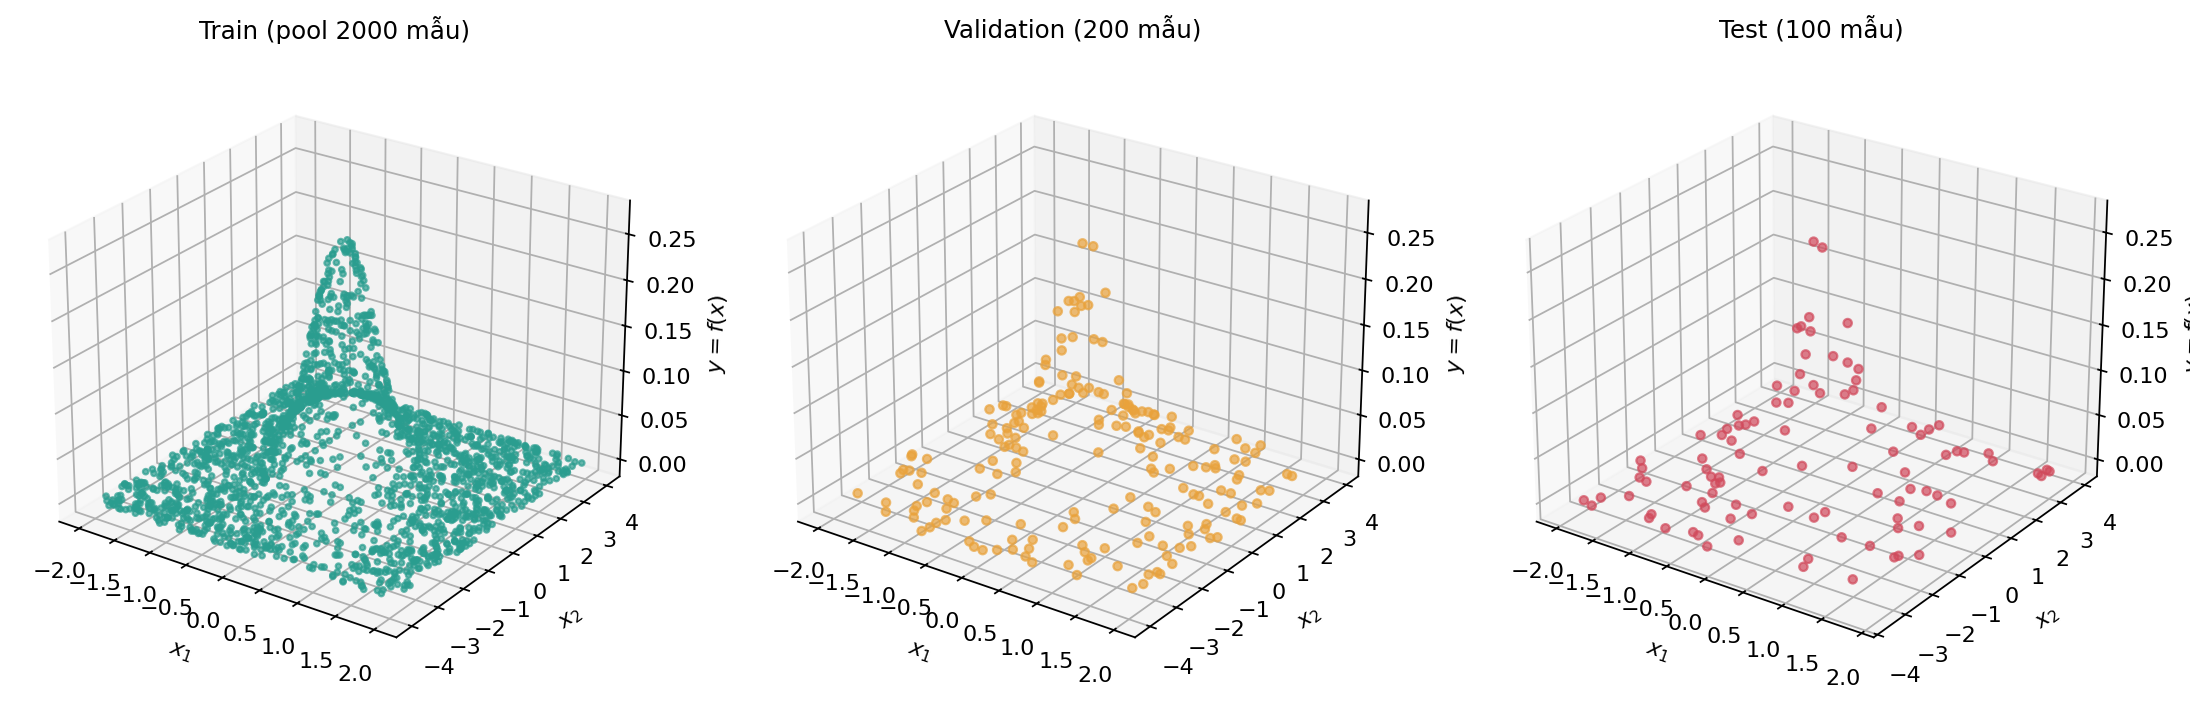

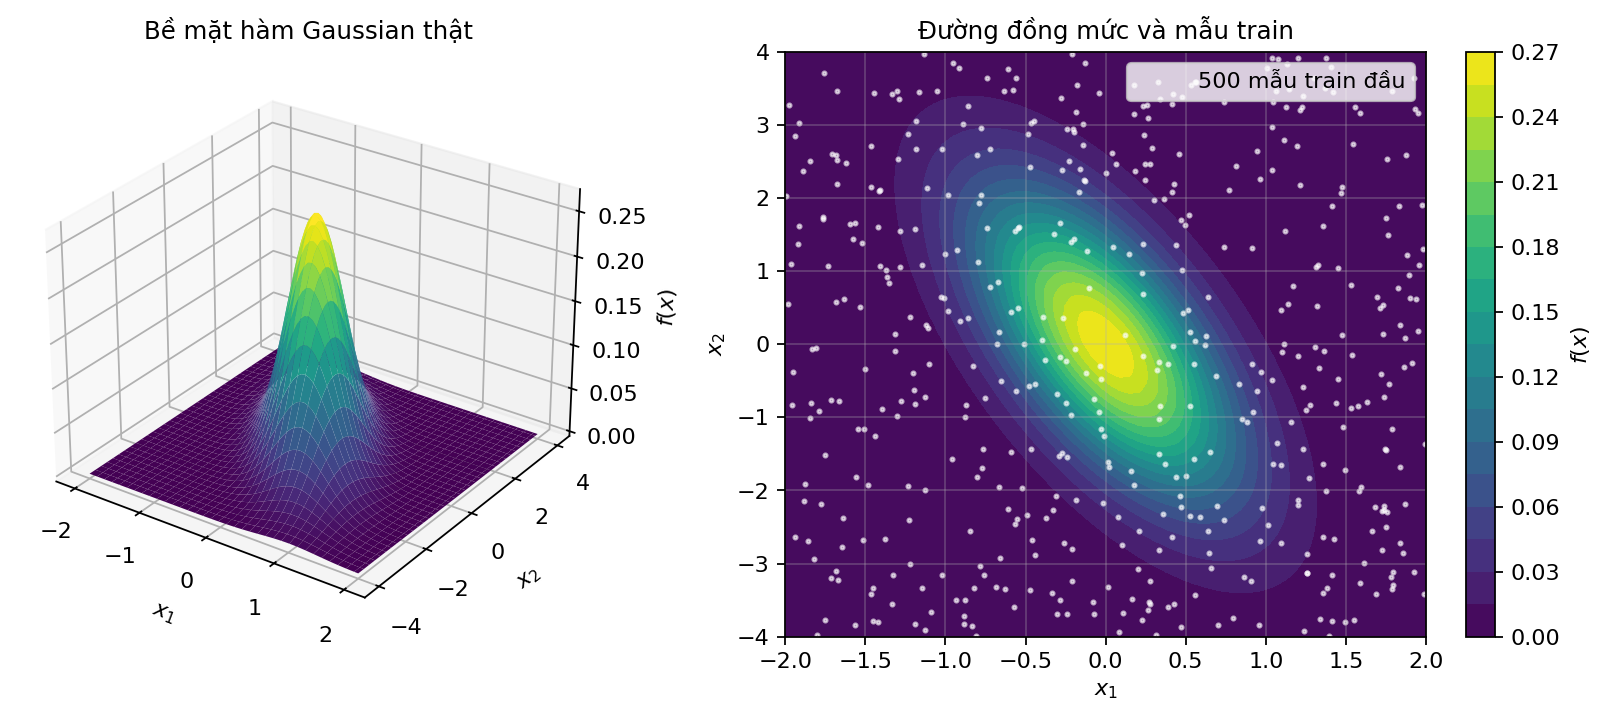

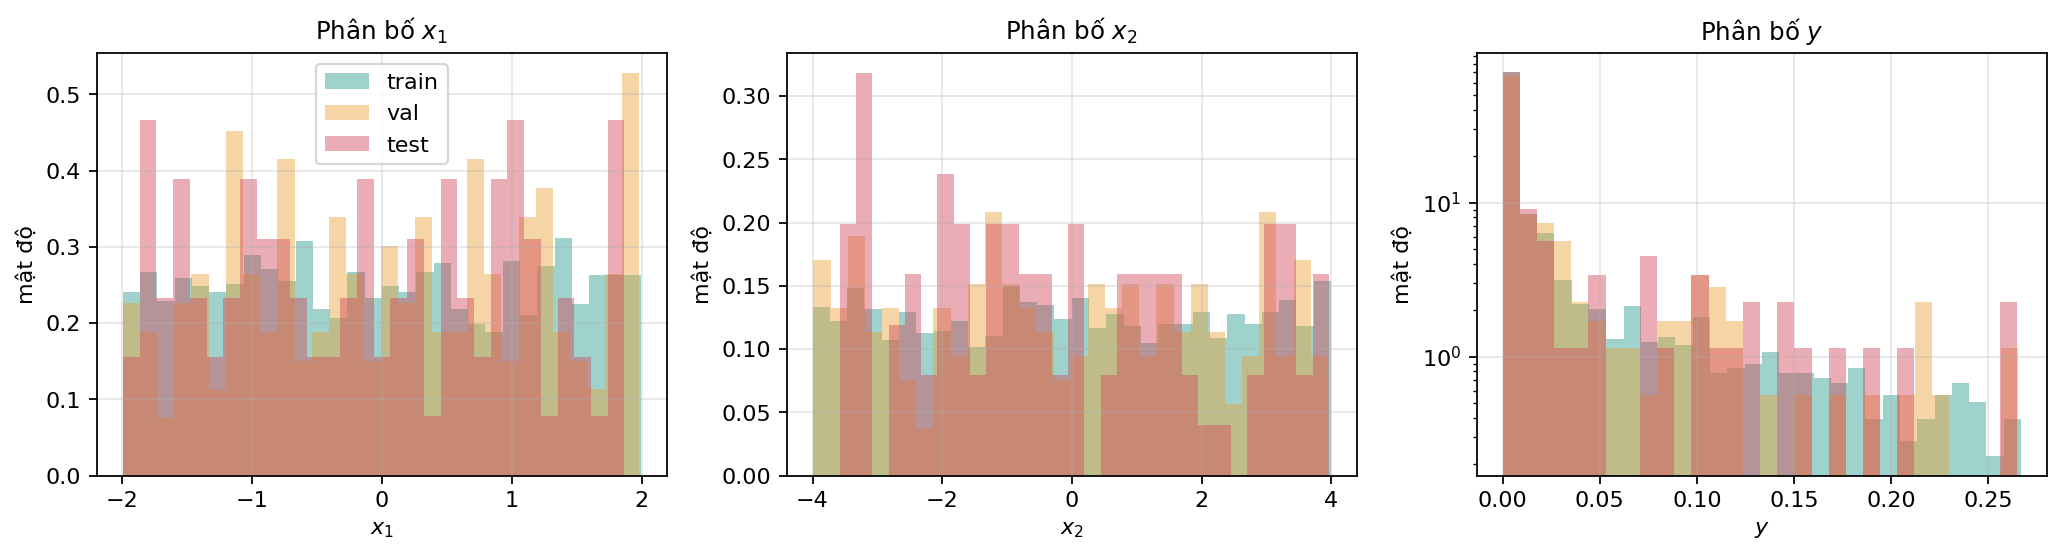

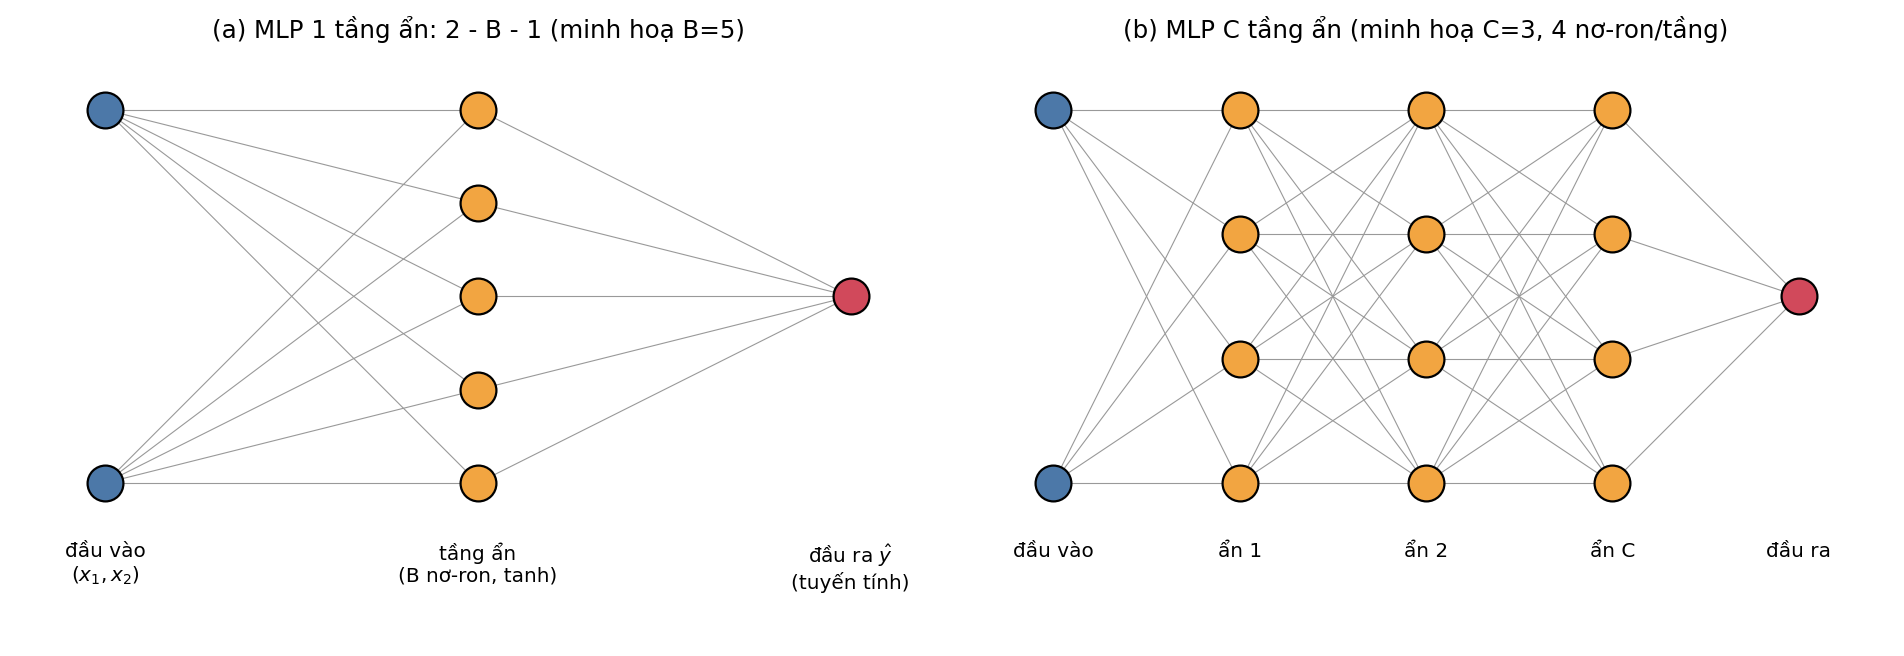

In [6]:
splits = load_splits(DATA_DIR)        # sinh (seed 2026) + lưu CSV nếu chưa có, rồi nạp
stats = describe(splits)
stats.to_csv(RES_DIR / "data_stats.csv", index=False)
display(stats.round(4))
fig_data(splits, FIG_DIR)             # scatter 3D train/val/test
fig_arch(FIG_DIR)                     # sơ đồ kiến trúc
# bề mặt hàm thật + đường đồng mức + phân bố x1, x2, y đã nằm trong fig_data (fig01–fig03)

In [7]:
# Kiểm tra: hàm Gaussian tự viết khớp SciPy
from scipy.stats import multivariate_normal as mvn
xx = np.random.default_rng(0).uniform(-3, 3, (50, 2))
print("max |sai khác so với scipy| =", np.abs(gaussian_pdf(xx) - mvn.pdf(xx, MU, COV)).max())
print("đỉnh f(0) =", gaussian_pdf([[0, 0]])[0], " (lý thuyết 1/(2π√0.35) = %.4f)" % (1 / (2 * np.pi * np.sqrt(0.35))))

max |sai khác so với scipy| = 6.938893903907228e-17
đỉnh f(0) = 0.26902095463038056  (lý thuyết 1/(2π√0.35) = 0.2690)


## 2. Mô hình MLP bằng 

In [8]:
"""MLP tuỳ biến số tầng ẩn / số nơ-ron bằng torch.nn.Module."""

ACTIVATIONS = {"tanh": nn.Tanh, "relu": nn.ReLU, "sigmoid": nn.Sigmoid}


class MLP(nn.Module):
    """in_dim -> [Linear + act] x len(hidden) -> Linear(out_dim). Đầu ra tuyến tính (bài toán hồi quy)."""

    def __init__(self, in_dim=2, hidden=(10,), out_dim=1, activation="tanh"):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers += [nn.Linear(d, h), ACTIVATIONS[activation]()]
            d = h
        layers.append(nn.Linear(d, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [9]:
# Minh hoạ: số tham số của MLP 2-10-1 (kỳ vọng 4B+1 = 41) và 3 tầng ẩn x 10
for h in [(10,), (10, 10, 10)]:
    m = MLP(hidden=h)
    print(h, "-> params:", sum(p.numel() for p in m.parameters()))
print(MLP(hidden=(10,)))

(10,) -> params: 41
(10, 10, 10) -> params: 261
MLP(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=10, bias=True)
    (1): Tanh()
    (2): Linear(in_features=10, out_features=1, bias=True)
  )
)


## 3. Huấn luyện và đánh giá



In [10]:
"""Engine chính: huấn luyện bằng PyTorch (nn.Module, DataLoader, MSELoss, Adam)."""


NAME = "pytorch"


def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def predict(model, X, device="cpu"):
    model.eval()
    return model(torch.as_tensor(X, dtype=torch.float32, device=device)).cpu().numpy().reshape(-1)


@torch.no_grad()
def eval_loss(model, X, y, criterion):
    model.eval()
    return criterion(model(X), y).item()


def state_to_numpy(model):
    """nn.Sequential: các nn.Linear lần lượt -> W0,b0,W1,b1,..."""
    st, i = {}, 0
    for m in model.net:
        if isinstance(m, nn.Linear):
            st[f"W{i}"] = m.weight.detach().cpu().numpy().astype(np.float64)
            st[f"b{i}"] = m.bias.detach().cpu().numpy().astype(np.float64)
            i += 1
    return st


def train_run(Xtr, ytr, Xva, yva, Xte, yte, hidden, activation="tanh", lr=1e-2,
              batch_size=64, epochs=300, patience=60, seed=0, device="cpu"):
    set_seed(seed)
    dev = torch.device(device)
    t = lambda a: torch.as_tensor(a, dtype=torch.float32, device=dev)
    Xtr_t, ytr_t = t(Xtr), t(ytr).unsqueeze(1)
    Xva_t, yva_t = t(Xva), t(yva).unsqueeze(1)

    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=batch_size, shuffle=True, generator=g)

    model = MLP(in_dim=Xtr.shape[1], hidden=tuple(hidden), activation=activation).to(dev)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history, best_val, best_epoch, best_state, bad = [], float("inf"), 0, None, 0
    t0 = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:               # vòng lặp huấn luyện tự viết
            optimizer.zero_grad()           # 1) xoá gradient cũ
            loss = criterion(model(xb), yb)  # 2) forward + loss
            loss.backward()                 # 3) backpropagation
            optimizer.step()                # 4) cập nhật tham số
        train_loss = eval_loss(model, Xtr_t, ytr_t, criterion)   # model.eval() + no_grad
        val_loss = eval_loss(model, Xva_t, yva_t, criterion)
        history.append(dict(epoch=epoch, train_loss=train_loss, val_loss=val_loss))
        if val_loss < best_val - 1e-12:     # checkpoint theo validation loss
            best_val, best_epoch, bad = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:
                break
    train_time = time.perf_counter() - t0

    model.load_state_dict(best_state)       # khôi phục checkpoint tốt nhất
    metrics = {k: regression_metrics(y, predict(model, X, device))
               for k, (X, y) in {"train": (Xtr, ytr), "val": (Xva, yva), "test": (Xte, yte)}.items()}
    return dict(history=history, best_epoch=best_epoch, epochs_run=len(history), train_time_s=train_time,
                state=state_to_numpy(model), metrics=metrics, torch_state=best_state)


def save_checkpoint(res, path, meta):
    torch.save({"state_dict": res["torch_state"], "meta": meta}, str(path) + ".pt")

best epoch: 1000 | thời gian: 56.3s
train MSE=7.644e-05  MAE=6.492e-03  RMSE=8.743e-03
val   MSE=7.154e-05  MAE=6.400e-03  RMSE=8.458e-03
test  MSE=7.860e-05  MAE=6.478e-03  RMSE=8.865e-03


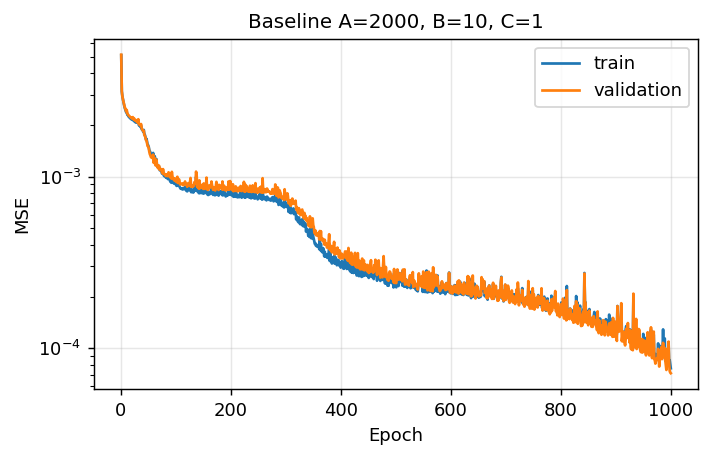

In [11]:
engine = types.SimpleNamespace(NAME=NAME, train_run=train_run, save_checkpoint=save_checkpoint)
(RES_DIR / "engine.txt").write_text(engine.NAME)

# ---- Demo: huấn luyện baseline (A=2000, B=10, C=1) 1 lần ----
Xtr, ytr = to_arrays(splits["train"], 2000); Xva, yva = to_arrays(splits["val"]); Xte, yte = to_arrays(splits["test"])
res = train_run(Xtr, ytr, Xva, yva, Xte, yte, hidden=(10,), lr=3e-3, batch_size=64,
                epochs=30 if QUICK else 1000, patience=100, seed=0, device=DEVICE)
print("best epoch:", res["best_epoch"], "| thời gian: %.1fs" % res["train_time_s"])
for k, v in res["metrics"].items():
    print(f"{k:5s} MSE={v['mse']:.3e}  MAE={v['mae']:.3e}  RMSE={v['rmse']:.3e}")
h = pd.DataFrame(res["history"])
plt.figure(figsize=(6, 3.5)); plt.plot(h.epoch, h.train_loss, label="train"); plt.plot(h.epoch, h.val_loss, label="validation")
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.grid(alpha=.3); plt.title("Baseline A=2000, B=10, C=1"); plt.show()

## 4. Ba nhóm thực nghiệm
**Baseline (công bố rõ):** tanh · Adam lr = 3e-3 (chọn bằng validation trong {3e-3, 1e-2, 3e-2}) · batch 64 · MSELoss · tối đa 1000 epoch + early stopping (patience 100) · seeds 0–4 · dữ liệu cố định (seed 2026).
Mỗi nhóm chỉ đổi yếu tố đang khảo sát:

| Nhóm | Biến đổi | Giữ cố định |
|---|---|---|
| **A** | A = 200, 400, …, 2000 | B = 10, C = 1 |
| **B** | B = 1…10 (+ 16, 32, 64) | A = 2000, C = 1 |
| **C** | C = 1…5 tầng ẩn | A = 2000, 10 nơ-ron/tầng |
| A2 *(đối chứng)* | như A nhưng epoch ∝ 2000/A (cân bằng số bước cập nhật) | |
| B2 *(đối chứng)* | như B nhưng A = 200 (để quan sát quá khớp) | |

Mỗi lần chạy lưu: cấu hình, log loss theo epoch (`results/logs/*.csv`), trọng số tốt nhất (`models/*.pt`) và chỉ số train/val/test (`results/runs_*.csv`, `results/summary_*.csv` = TB ± std).

In [12]:

from pathlib import Path
import pandas as pd

BASE = dict(activation="tanh", lr=3e-3, batch_size=64, epochs=1000, patience=100)
B_LIST = list(range(1, 11)) + [16, 32, 64]     # B = 1..10 mở rộng thêm 16, 32, 64
A_LIST = list(range(200, 2001, 200))
C_LIST = [1, 2, 3, 4, 5]
W_BASE = 10                                     # số nơ-ron mỗi tầng ẩn ở nhóm C và A


def _plans():
    """exp -> list(tag, A, hidden, epochs)."""
    E = BASE["epochs"]
    scale = lambda A: int(E * 2000 / A)         # cân bằng số bước cập nhật theo A
    return {
        "A":  [(f"A{A}", A, (W_BASE,), E) for A in A_LIST],
        "A2": [(f"A{A}", A, (W_BASE,), scale(A)) for A in A_LIST],
        "B":  [(f"B{B}", 2000, (B,), E) for B in B_LIST],
        "B2": [(f"B{B}", 200, (B,), scale(200)) for B in B_LIST],
        "C":  [(f"C{C}", 2000, (W_BASE,) * C, E) for C in C_LIST],
    }


def run_group(engine, exp, splits, out_dir, seeds, device="cpu", quick=False, save_models=True, verbose=True):
    out_dir = Path(out_dir)
    (out_dir / "results" / "logs").mkdir(parents=True, exist_ok=True)
    (out_dir / "models").mkdir(parents=True, exist_ok=True)
    Xva, yva = to_arrays(splits["val"])
    Xte, yte = to_arrays(splits["test"])
    rows = []
    for tag, A, hidden, epochs in _plans()[exp]:
        Xtr, ytr = to_arrays(splits["train"], A)
        if quick:
            epochs = min(epochs, 30)
        pat = max(BASE["patience"], epochs // 10)
        for seed in seeds:
            res = engine.train_run(Xtr, ytr, Xva, yva, Xte, yte, hidden, BASE["activation"], BASE["lr"],
                                   BASE["batch_size"], epochs, pat, seed, device)
            m = res["metrics"]
            row = dict(exp=exp, tag=tag, A=A, B=hidden[0] if len(hidden) == 1 else W_BASE, C=len(hidden),
                       hidden=str(list(hidden)), seed=seed, engine=engine.NAME, lr=BASE["lr"],
                       batch_size=BASE["batch_size"], epochs_max=epochs, patience=pat,
                       epochs_run=res["epochs_run"], best_epoch=res["best_epoch"],
                       train_time_s=round(res["train_time_s"], 4),
                       train_mse=m["train"]["mse"], val_mse=m["val"]["mse"], test_mse=m["test"]["mse"],
                       train_mae=m["train"]["mae"], val_mae=m["val"]["mae"], test_mae=m["test"]["mae"],
                       test_rmse=m["test"]["rmse"], params=sum(w.size for w in res["state"].values()))
            rows.append(row)
            pd.DataFrame(res["history"]).to_csv(out_dir / "results" / "logs" / f"{exp}_{tag}_s{seed}.csv", index=False)
            if save_models:
                engine.save_checkpoint(res, out_dir / "models" / f"{exp}_{tag}_s{seed}",
                                       dict(hidden=hidden, activation=BASE["activation"], seed=seed))
            # lưu state để dựng hình cuối (không ghi ra đĩa ở đây)
            row["_state"] = res["state"]
        if verbose:
            r = pd.DataFrame([{k: v for k, v in x.items() if k != "_state"} for x in rows if x["tag"] == tag])
            print(f"[{exp}] {tag:5s} A={A:4d} hidden={list(hidden)} val={r.val_mse.mean():.3e} "
                  f"test={r.test_mse.mean():.3e} time={r.train_time_s.mean():.1f}s", flush=True)
    df = pd.DataFrame([{k: v for k, v in x.items() if k != "_state"} for x in rows])
    df.to_csv(out_dir / "results" / f"runs_{exp}.csv", index=False)
    summarize(df).to_csv(out_dir / "results" / f"summary_{exp}.csv", index=False)
    return df, rows


def summarize(df):
    df = df.assign(ms_per_epoch=df.train_time_s / df.epochs_run * 1000.0)
    cols = ["ms_per_epoch", "train_mse", "val_mse", "test_mse", "train_mae", "val_mae", "test_mae", "test_rmse",
            "train_time_s", "best_epoch", "epochs_run", "params"]
    g = df.groupby(["exp", "tag", "A", "B", "C"], sort=False)[cols].agg(["mean", "std"])
    g.columns = [f"{a}_{b}" for a, b in g.columns]
    g["n_seeds"] = df.groupby(["exp", "tag", "A", "B", "C"], sort=False).size()
    return g.reset_index()

In [13]:
def run(exp):
    df, _ = run_group(engine, exp, splits, ROOT, SEEDS, DEVICE, QUICK)
    s = pd.read_csv(RES_DIR / f"summary_{exp}.csv")
    display(s[["tag", "A", "B", "C", "train_mse_mean", "val_mse_mean", "test_mse_mean", "test_mse_std",
               "test_mae_mean", "test_rmse_mean", "train_time_s_mean", "best_epoch_mean"]])
    return s

### 4.1 Nhóm A – số mẫu huấn luyện

In [14]:
sA = run("A")

[A] A200  A= 200 hidden=[10] val=9.582e-04 test=1.096e-03 time=7.2s
[A] A400  A= 400 hidden=[10] val=6.619e-04 test=6.825e-04 time=12.3s
[A] A600  A= 600 hidden=[10] val=3.889e-04 test=4.111e-04 time=17.6s
[A] A800  A= 800 hidden=[10] val=2.607e-04 test=2.774e-04 time=23.1s
[A] A1000 A=1000 hidden=[10] val=1.853e-04 test=2.031e-04 time=28.9s
[A] A1200 A=1200 hidden=[10] val=1.394e-04 test=1.508e-04 time=33.3s
[A] A1400 A=1400 hidden=[10] val=1.161e-04 test=1.167e-04 time=38.9s
[A] A1600 A=1600 hidden=[10] val=7.310e-05 test=8.010e-05 time=44.9s
[A] A1800 A=1800 hidden=[10] val=9.513e-05 test=9.971e-05 time=62.4s
[A] A2000 A=2000 hidden=[10] val=5.031e-05 test=5.064e-05 time=65.9s


,tag,A,B,C,train_mse_mean,val_mse_mean,test_mse_mean,test_mse_std,test_mae_mean,test_rmse_mean,train_time_s_mean,best_epoch_mean
0,A200,200,10,1,0.000697,0.000958,0.001096,0.000250,0.023837,0.032946,7.16302,993.0
1,A400,400,10,1,0.000517,0.000662,0.000682,0.000230,0.018759,0.025793,12.28928,961.2
2,A600,600,10,1,0.000332,0.000389,0.000411,0.000268,0.014045,0.019330,17.57470,964.6
3,A800,800,10,1,0.000245,0.000261,0.000277,0.000203,0.011471,0.015670,23.07978,994.8
4,A1000,1000,10,1,0.000173,0.000185,0.000203,0.000050,0.010224,0.014166,28.91766,993.0
5,A1200,1200,10,1,0.000138,0.000139,0.000151,0.000087,0.008635,0.011747,33.32422,984.8
6,A1400,1400,10,1,0.000109,0.000116,0.000117,0.000062,0.007631,0.010498,38.92932,995.2
7,A1600,1600,10,1,0.000072,0.000073,0.000080,0.000060,0.006425,0.008533,44.92806,997.0
8,A1800,1800,10,1,0.000095,0.000095,0.000100,0.000062,0.007177,0.009602,62.44334,981.4
9,A2000,2000,10,1,0.000049,0.000050,0.000051,0.000016,0.005363,0.007058,65.85394,992.2


### 4.2 Đối chứng A2 – cân bằng số bước cập nhật theo A

In [15]:
sA2 = run("A2")

[A2] A200  A= 200 hidden=[10] val=1.009e-04 test=1.087e-04 time=70.6s
[A2] A400  A= 400 hidden=[10] val=8.352e-05 test=8.573e-05 time=61.8s
[A2] A600  A= 600 hidden=[10] val=6.876e-05 test=6.968e-05 time=58.7s
[A2] A800  A= 800 hidden=[10] val=5.189e-05 test=5.055e-05 time=57.1s
[A2] A1000 A=1000 hidden=[10] val=5.963e-05 test=6.234e-05 time=56.2s
[A2] A1200 A=1200 hidden=[10] val=4.442e-05 test=4.537e-05 time=63.7s
[A2] A1400 A=1400 hidden=[10] val=5.765e-05 test=5.407e-05 time=59.7s
[A2] A1600 A=1600 hidden=[10] val=4.821e-05 test=5.283e-05 time=60.7s
[A2] A1800 A=1800 hidden=[10] val=8.227e-05 test=8.762e-05 time=55.8s
[A2] A2000 A=2000 hidden=[10] val=5.031e-05 test=5.064e-05 time=55.6s


,tag,A,B,C,train_mse_mean,val_mse_mean,test_mse_mean,test_mse_std,test_mae_mean,test_rmse_mean,train_time_s_mean,best_epoch_mean
0,A200,200,10,1,0.000066,0.000101,0.000109,0.000048,0.007419,0.010220,70.57874,9794.8
1,A400,400,10,1,0.000062,0.000084,0.000086,0.000050,0.006465,0.008975,61.82912,4957.2
2,A600,600,10,1,0.000054,0.000069,0.000070,0.000028,0.006265,0.008192,58.68384,3304.6
3,A800,800,10,1,0.000048,0.000052,0.000051,0.000018,0.005337,0.007019,57.12368,2495.0
4,A1000,1000,10,1,0.000054,0.000060,0.000062,0.000036,0.005822,0.007667,56.16436,1991.8
5,A1200,1200,10,1,0.000042,0.000044,0.000045,0.000012,0.004978,0.006684,63.71192,1654.4
6,A1400,1400,10,1,0.000052,0.000058,0.000054,0.000009,0.005480,0.007336,59.71304,1401.4
7,A1600,1600,10,1,0.000048,0.000048,0.000053,0.000030,0.005360,0.007070,60.71318,1227.4
8,A1800,1800,10,1,0.000083,0.000082,0.000088,0.000049,0.006851,0.009066,55.76562,1090.0
9,A2000,2000,10,1,0.000049,0.000050,0.000051,0.000016,0.005363,0.007058,55.58910,992.2


### 4.3 Nhóm B – số nơ-ron tầng ẩn

In [16]:
sB = run("B")

[B] B1    A=2000 hidden=[1] val=3.018e-03 test=3.436e-03 time=18.9s
[B] B2    A=2000 hidden=[2] val=1.870e-03 test=1.962e-03 time=46.8s
[B] B3    A=2000 hidden=[3] val=1.016e-03 test=1.033e-03 time=55.9s
[B] B4    A=2000 hidden=[4] val=8.039e-04 test=7.940e-04 time=47.1s
[B] B5    A=2000 hidden=[5] val=6.925e-04 test=6.708e-04 time=52.7s
[B] B6    A=2000 hidden=[6] val=3.538e-04 test=3.514e-04 time=52.9s
[B] B7    A=2000 hidden=[7] val=1.617e-04 test=1.745e-04 time=57.7s
[B] B8    A=2000 hidden=[8] val=1.120e-04 test=1.105e-04 time=57.7s
[B] B9    A=2000 hidden=[9] val=2.220e-04 test=2.225e-04 time=52.1s
[B] B10   A=2000 hidden=[10] val=5.031e-05 test=5.064e-05 time=57.9s
[B] B16   A=2000 hidden=[16] val=3.425e-05 test=3.024e-05 time=57.8s
[B] B32   A=2000 hidden=[32] val=2.626e-05 test=2.531e-05 time=56.9s
[B] B64   A=2000 hidden=[64] val=1.179e-05 test=9.518e-06 time=59.2s


,tag,A,B,C,train_mse_mean,val_mse_mean,test_mse_mean,test_mse_std,test_mae_mean,test_rmse_mean,train_time_s_mean,best_epoch_mean
0,B1,2000,1,1,0.003058,0.003018,0.003436,0.000005,0.041844,0.058617,18.88158,226.0
1,B2,2000,2,1,0.001780,0.001870,0.001962,0.000822,0.025480,0.043666,46.80538,639.8
2,B3,2000,3,1,0.000973,0.001016,0.001033,0.000506,0.018806,0.031387,55.87120,817.6
3,B4,2000,4,1,0.000756,0.000804,0.000794,0.000464,0.018777,0.027357,47.09422,738.2
4,B5,2000,5,1,0.000640,0.000692,0.000671,0.000552,0.016044,0.024415,52.71336,868.6
5,B6,2000,6,1,0.000336,0.000354,0.000351,0.000256,0.013429,0.017927,52.87808,869.2
6,B7,2000,7,1,0.000163,0.000162,0.000175,0.000099,0.009749,0.012781,57.72654,990.4
7,B8,2000,8,1,0.000110,0.000112,0.000111,0.000059,0.007708,0.010232,57.69864,990.2
8,B9,2000,9,1,0.000207,0.000222,0.000222,0.000321,0.009499,0.012686,52.12234,877.4
9,B10,2000,10,1,0.000049,0.000050,0.000051,0.000016,0.005363,0.007058,57.93788,992.2


### 4.4 Đối chứng B2 – A = 200

In [17]:
sB2 = run("B2")

[B2] B1    A= 200 hidden=[1] val=3.018e-03 test=3.439e-03 time=14.9s
[B2] B2    A= 200 hidden=[2] val=2.172e-03 test=2.359e-03 time=41.6s
[B2] B3    A= 200 hidden=[3] val=1.044e-03 test=1.078e-03 time=70.8s
[B2] B4    A= 200 hidden=[4] val=6.382e-04 test=6.691e-04 time=69.5s
[B2] B5    A= 200 hidden=[5] val=4.744e-04 test=4.972e-04 time=63.2s
[B2] B6    A= 200 hidden=[6] val=3.965e-04 test=4.211e-04 time=57.1s
[B2] B7    A= 200 hidden=[7] val=2.120e-04 test=2.243e-04 time=68.2s
[B2] B8    A= 200 hidden=[8] val=1.698e-04 test=1.658e-04 time=70.2s
[B2] B9    A= 200 hidden=[9] val=2.454e-04 test=2.502e-04 time=60.8s
[B2] B10   A= 200 hidden=[10] val=1.009e-04 test=1.087e-04 time=70.3s
[B2] B16   A= 200 hidden=[16] val=6.636e-05 test=6.405e-05 time=70.4s
[B2] B32   A= 200 hidden=[32] val=6.012e-05 test=5.952e-05 time=67.6s
[B2] B64   A= 200 hidden=[64] val=3.204e-05 test=3.155e-05 time=71.4s


,tag,A,B,C,train_mse_mean,val_mse_mean,test_mse_mean,test_mse_std,test_mae_mean,test_rmse_mean,train_time_s_mean,best_epoch_mean
0,B1,200,1,1,0.002352,0.003018,0.003439,0.000002,0.041801,0.058642,14.85564,1279.6
1,B2,200,2,1,0.001640,0.002172,0.002359,0.000989,0.030211,0.047740,41.60206,3856.4
2,B3,200,3,1,0.000732,0.001044,0.001078,0.000512,0.018745,0.032111,70.76950,7455.0
3,B4,200,4,1,0.000452,0.000638,0.000669,0.000149,0.018915,0.025742,69.54084,8602.0
4,B5,200,5,1,0.000347,0.000474,0.000497,0.000193,0.015494,0.022020,63.22450,8749.0
5,B6,200,6,1,0.000273,0.000396,0.000421,0.000282,0.014469,0.019780,57.08378,7656.0
6,B7,200,7,1,0.000147,0.000212,0.000224,0.000065,0.011098,0.014824,68.22444,9246.0
7,B8,200,8,1,0.000107,0.000170,0.000166,0.000083,0.009140,0.012594,70.17042,9925.0
8,B9,200,9,1,0.000165,0.000245,0.000250,0.000338,0.010231,0.013774,60.80246,8026.6
9,B10,200,10,1,0.000066,0.000101,0.000109,0.000048,0.007419,0.010220,70.27208,9794.8


### 4.5 Nhóm C – số tầng ẩn (đo cả thời gian huấn luyện)

In [18]:
sC = run("C")

[C] C1    A=2000 hidden=[10] val=5.031e-05 test=5.064e-05 time=58.6s
[C] C2    A=2000 hidden=[10, 10] val=5.411e-07 test=5.363e-07 time=31.1s
[C] C3    A=2000 hidden=[10, 10, 10] val=4.170e-07 test=5.213e-07 time=28.1s
[C] C4    A=2000 hidden=[10, 10, 10, 10] val=5.387e-07 test=6.731e-07 time=25.2s
[C] C5    A=2000 hidden=[10, 10, 10, 10, 10] val=6.441e-07 test=8.593e-07 time=25.3s


,tag,A,B,C,train_mse_mean,val_mse_mean,test_mse_mean,test_mse_std,test_mae_mean,test_rmse_mean,train_time_s_mean,best_epoch_mean
0,C1,2000,10,1,4.877870e-05,5.031146e-05,5.064239e-05,1.569992e-05,0.005363,0.007058,58.63738,992.2
1,C2,2000,10,2,5.713877e-07,5.410652e-07,5.362902e-07,2.658085e-07,0.000550,0.000714,31.08000,871.2
2,C3,2000,10,3,4.583334e-07,4.170179e-07,5.212887e-07,2.831205e-07,0.000510,0.000702,28.11464,609.6
3,C4,2000,10,4,5.074056e-07,5.387303e-07,6.731061e-07,1.679609e-07,0.000595,0.000815,25.21050,471.6
4,C5,2000,10,5,6.225151e-07,6.440798e-07,8.592575e-07,3.050903e-07,0.000607,0.000915,25.30214,407.8


## 5. Hình tổng hợp, chọn mô hình cuối và minh hoạ xấp xỉ
Mô hình cuối được chọn **theo validation** (cấu hình có val MSE trung bình thấp nhất trong nhóm B và C, A = 2000; lần chạy có val MSE nhỏ nhất của cấu hình đó). Chỉ sau khi chọn xong mới báo cáo kết quả test.

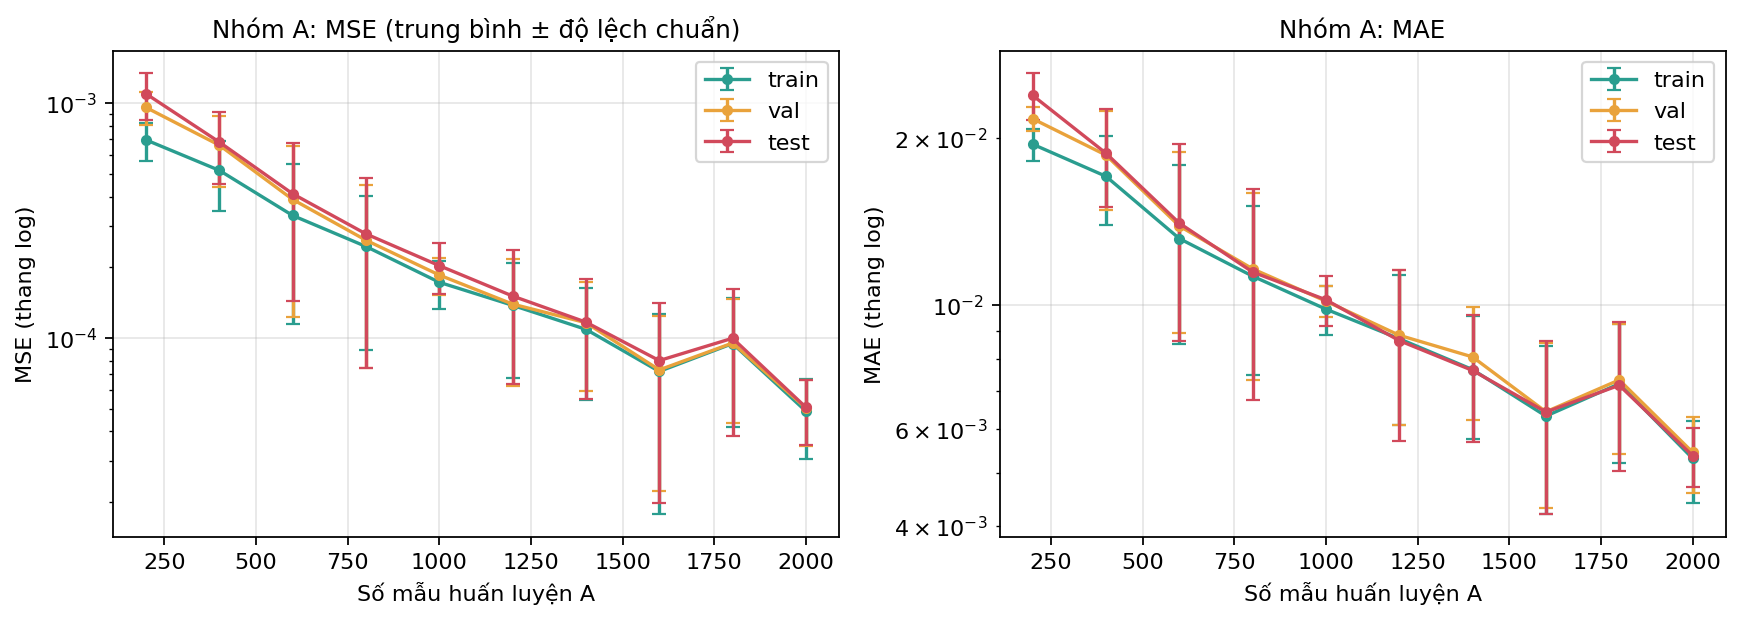

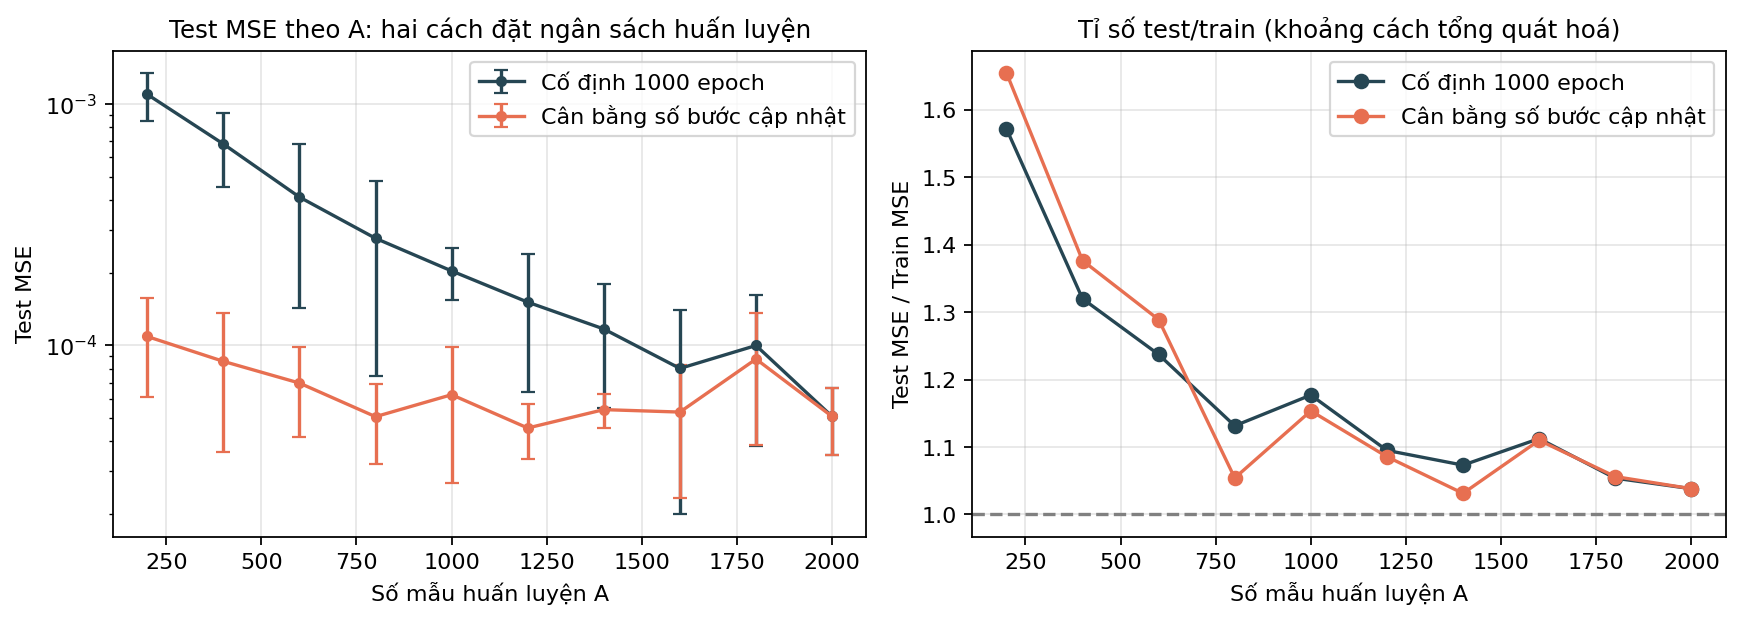

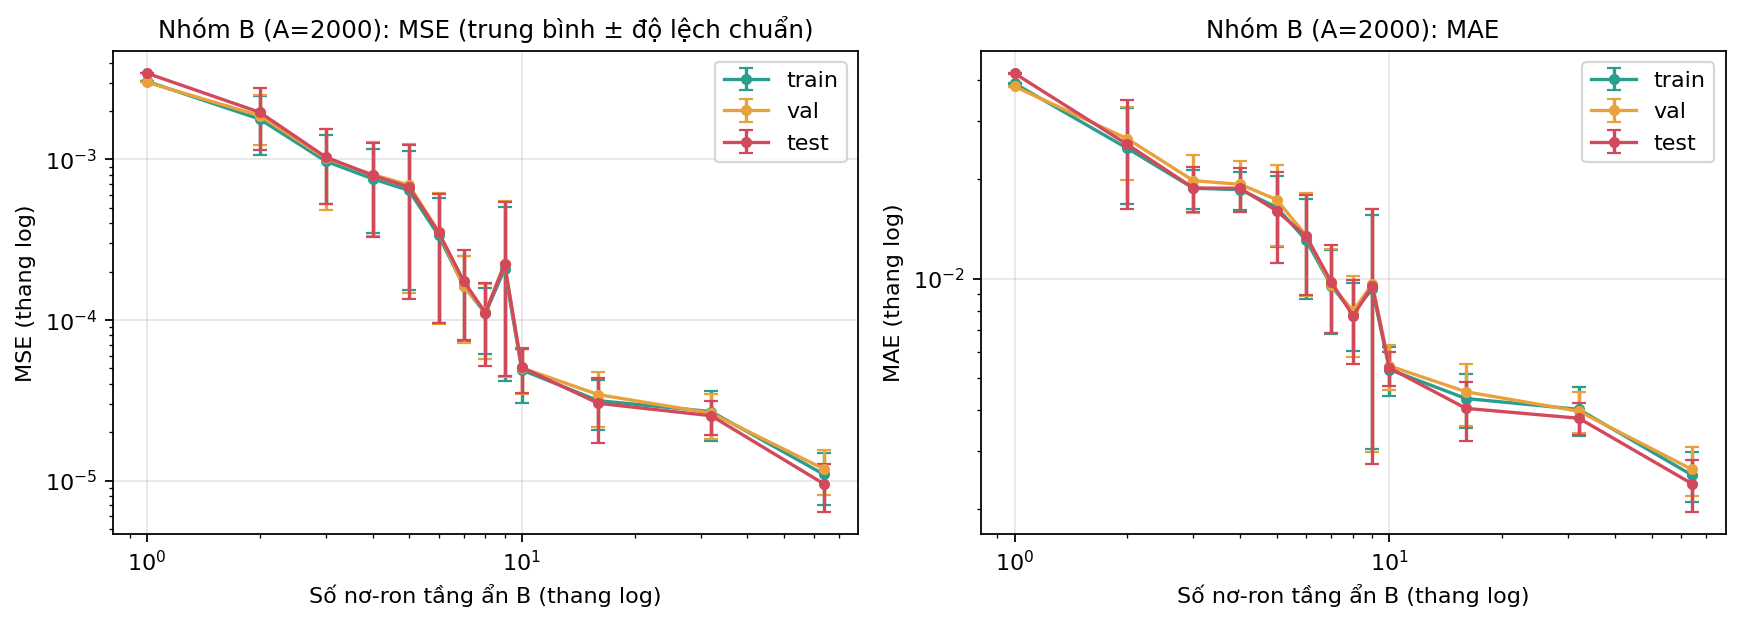

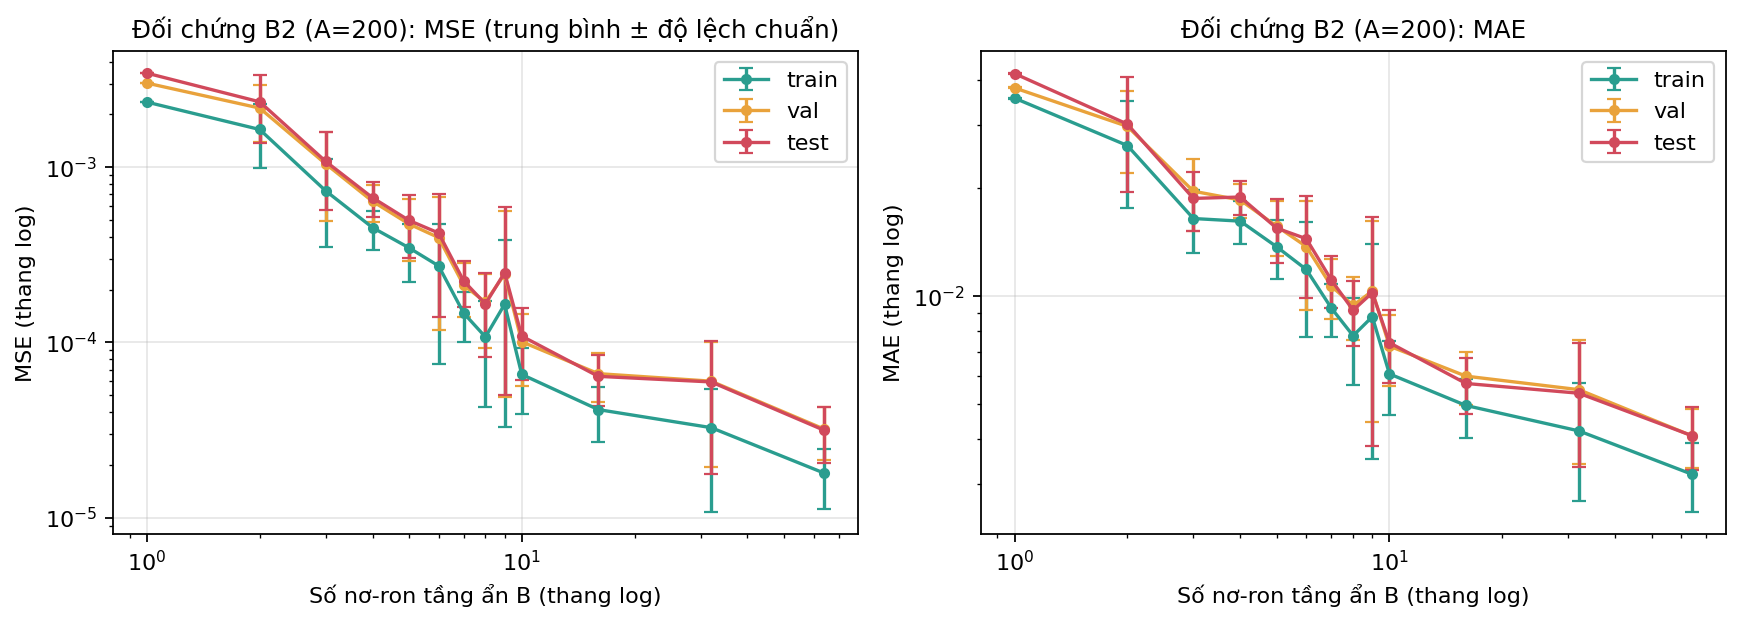

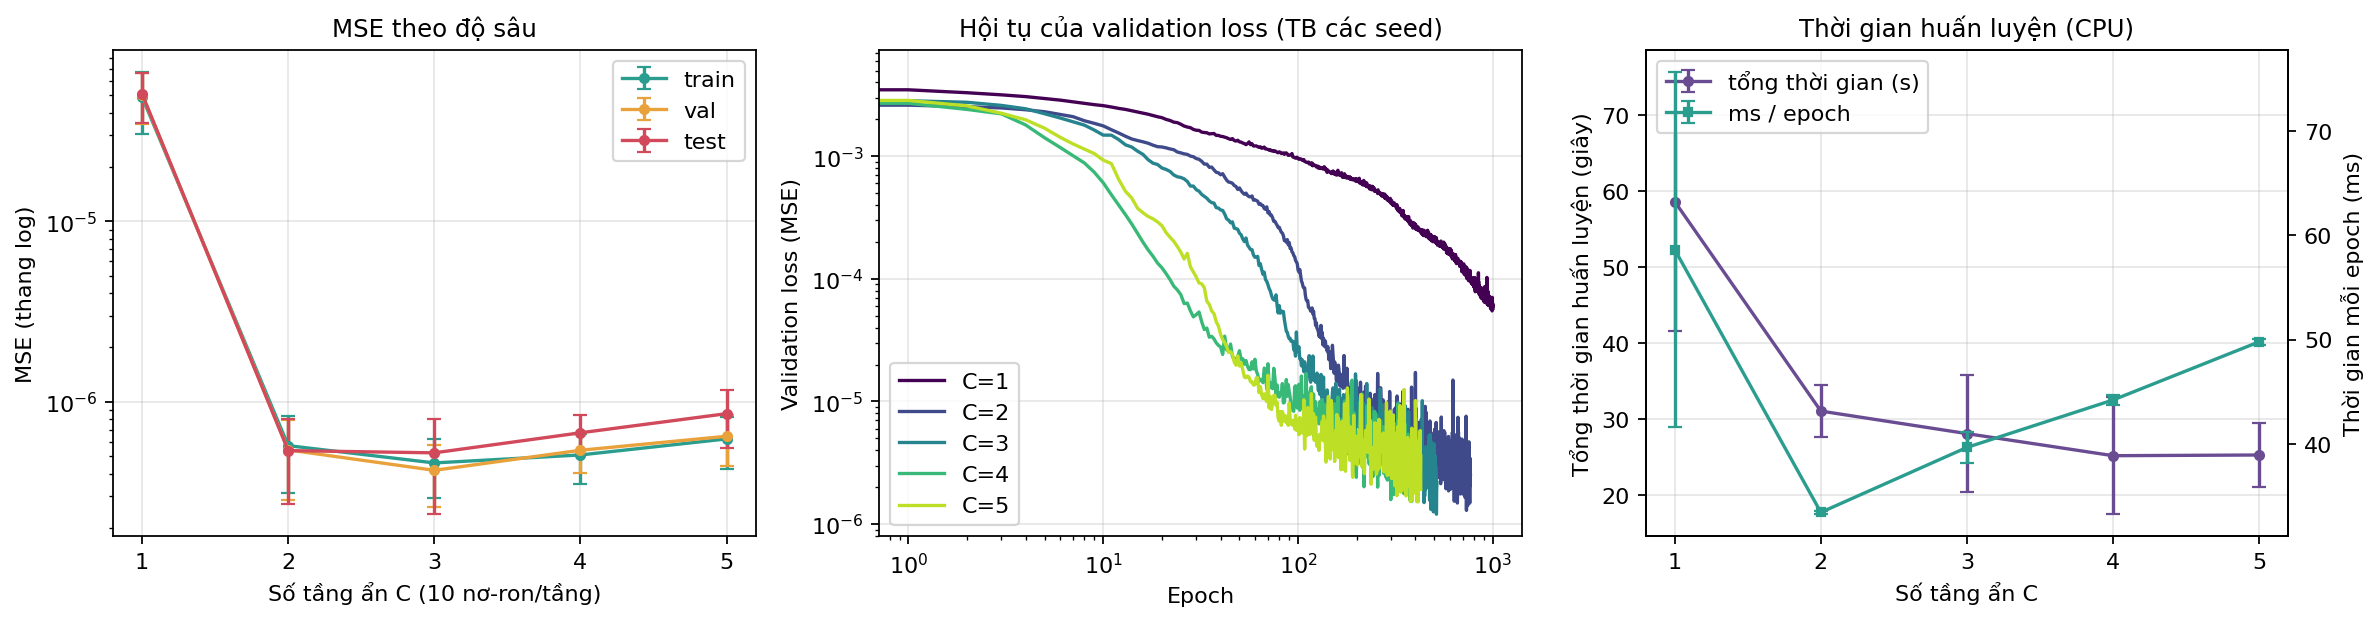

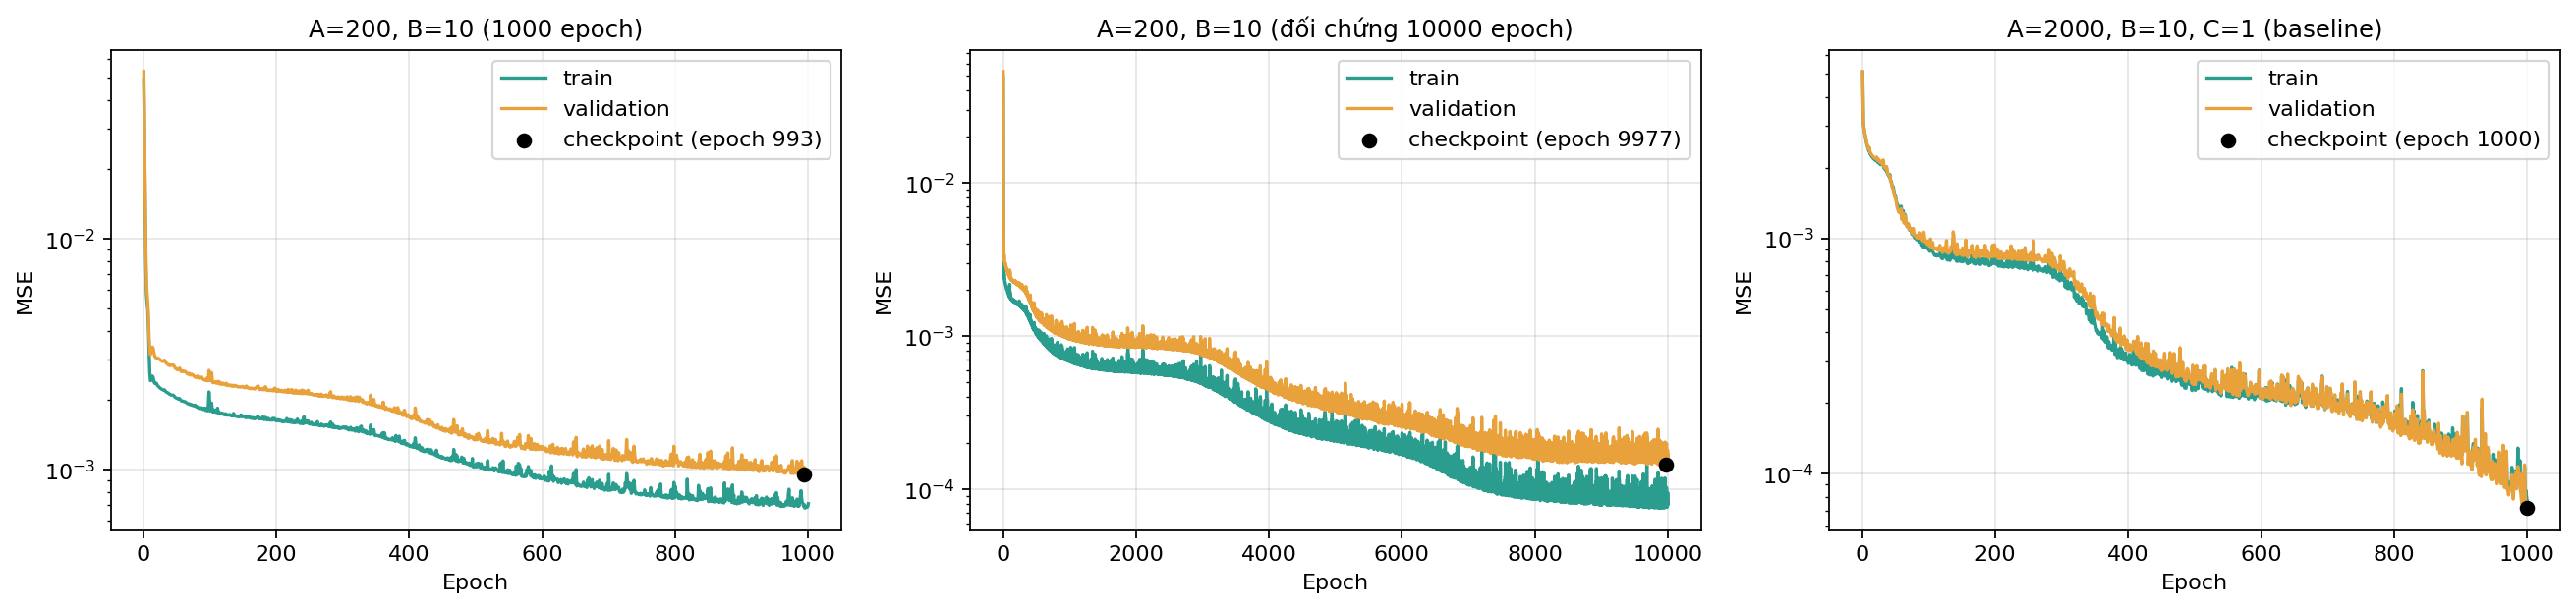

In [19]:
S = {"A": sA, "A2": sA2, "B": sB, "B2": sB2, "C": sC}
LOGS = RES_DIR / "logs"
fig_sweep(S["A"], "A", "Số mẫu huấn luyện A", FIG_DIR / "fig04_expA.png", "Nhóm A")
fig_A_compare(S["A"], S["A2"], FIG_DIR / "fig05_expA_control.png")
fig_sweep(S["B"], "B", "Số nơ-ron tầng ẩn B (thang log)", FIG_DIR / "fig06_expB.png", "Nhóm B (A=2000)", logx=True)
fig_sweep(S["B2"], "B", "Số nơ-ron tầng ẩn B (thang log)", FIG_DIR / "fig07_expB2.png", "Đối chứng B2 (A=200)", logx=True)
fig_C(S["C"], LOGS, SEEDS, FIG_DIR / "fig08_expC.png")
fig_curves(LOGS, FIG_DIR / "fig09_loss_curves.png",
           [("A", "A200", "A=200, B=10 (1000 epoch)"), ("A2", "A200", "A=200, B=10 (đối chứng 10000 epoch)"),
            ("C", "C1", "A=2000, B=10, C=1 (baseline)")])

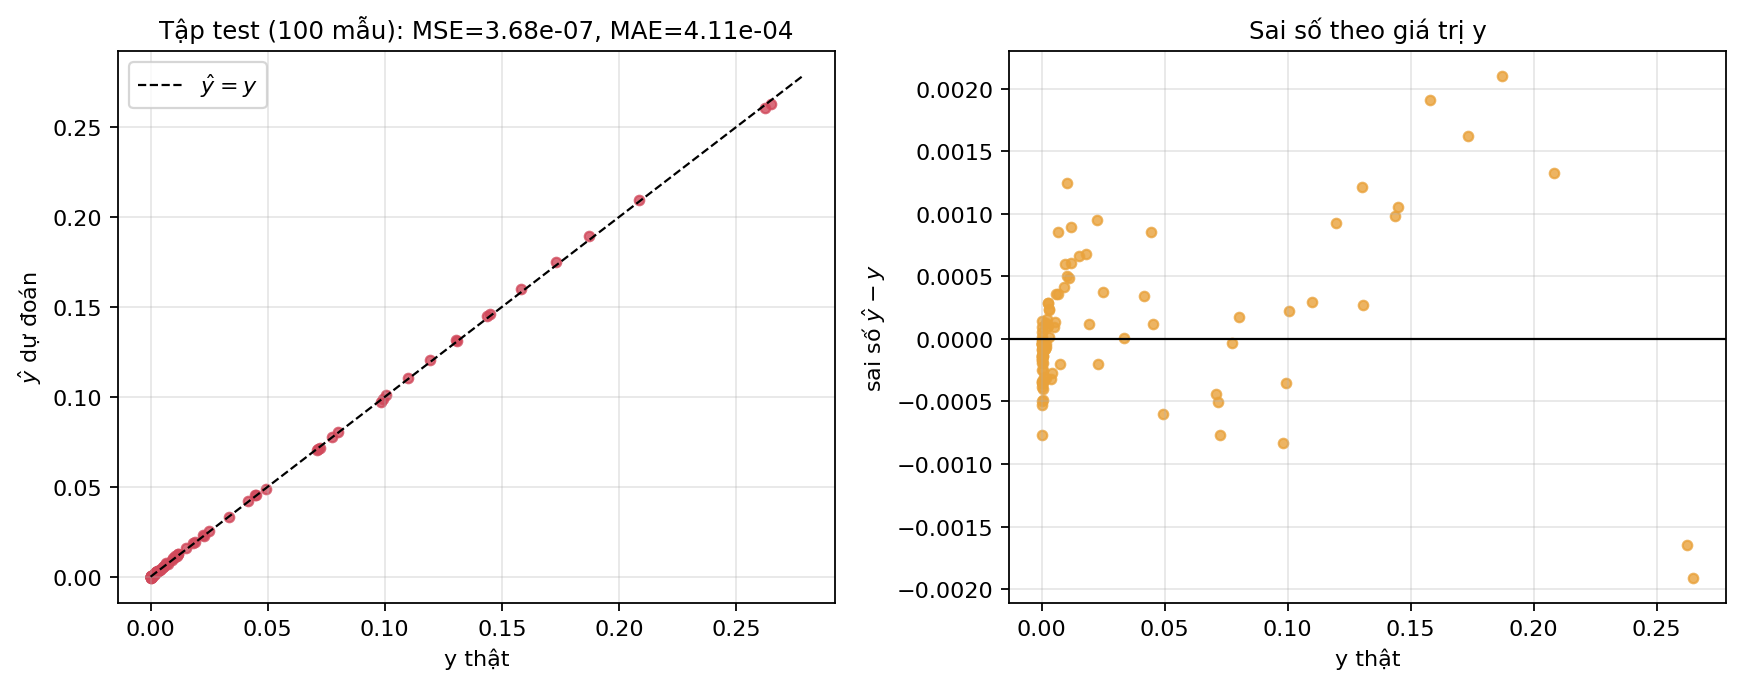

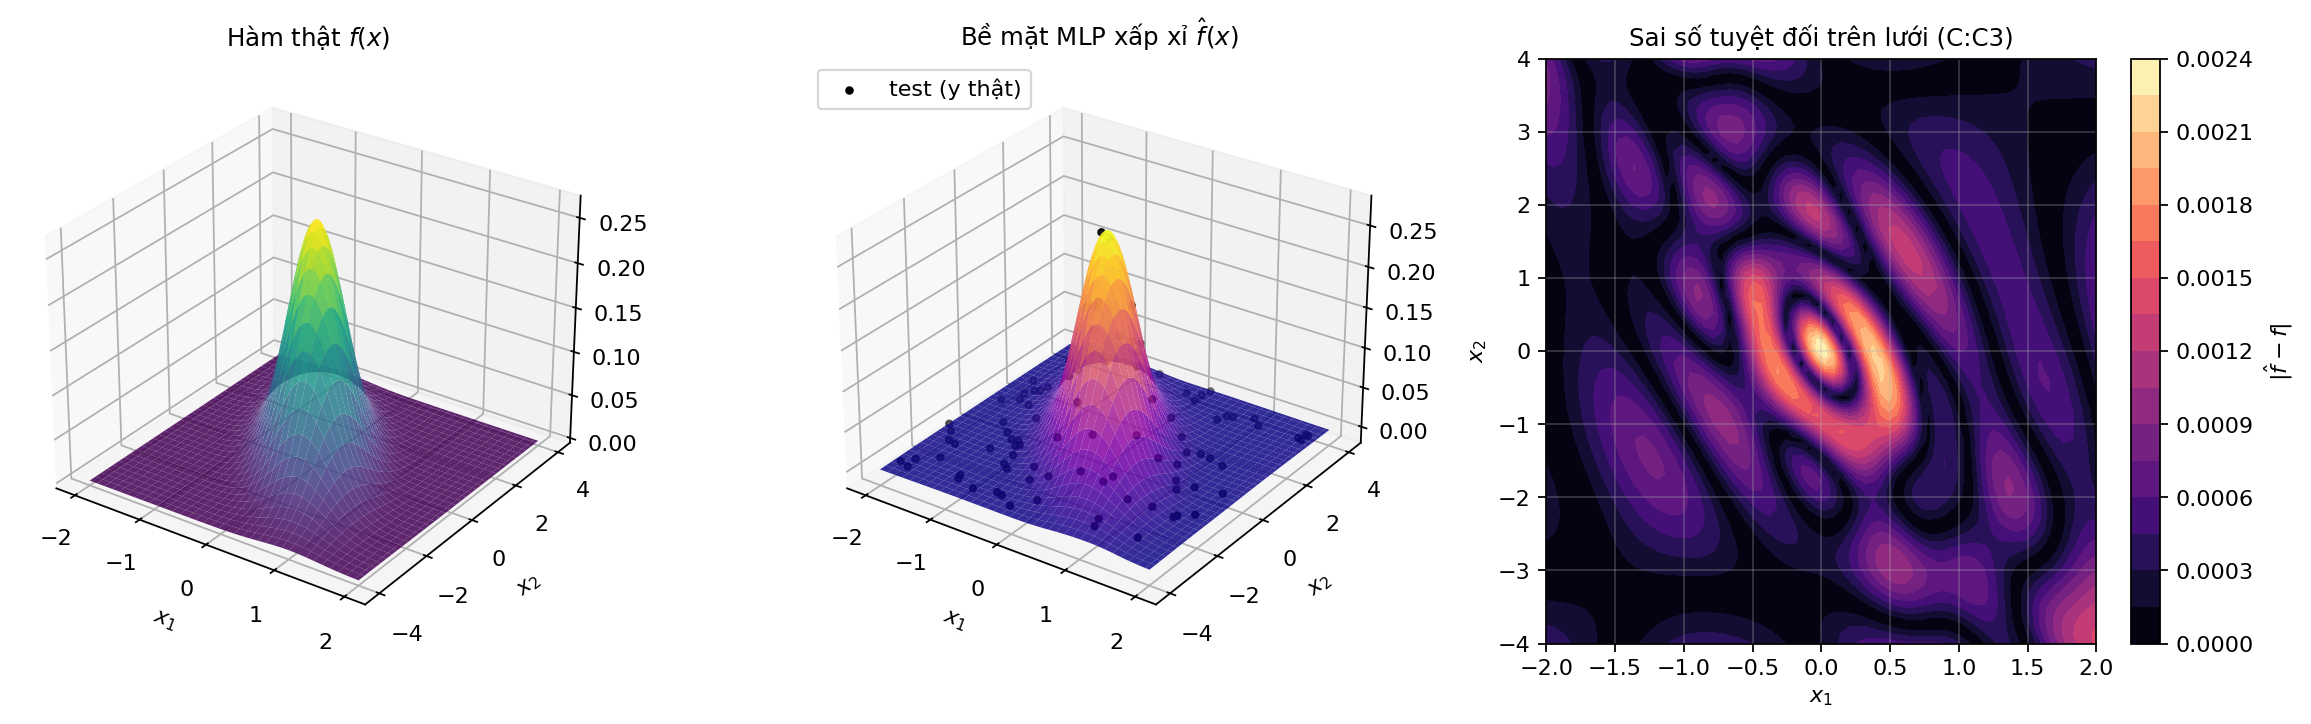

Mô hình được chọn (theo validation): {'model': 'C:C3', 'seed': 4, 'hidden': '[10, 10, 10]', 'val_mse': 2.4112661336806264e-07, 'test_mse': 3.68011906457062e-07, 'test_mae': 0.0004105340948145, 'test_rmse': 0.0006066398490513, 'max_abs_err': 0.0023496470141832204, 'mean_abs_err': 0.0004022863160807448}


In [20]:
def load_state(base):
    """Nạp trọng số đã lưu (.pt của PyTorch hoặc .npz) -> dict W0,b0,W1,b1,... để dựng bề mặt xấp xỉ."""
    base = Path(base)
    if base.with_suffix(".pt").exists():
        ck = torch.load(str(base.with_suffix(".pt")), map_location="cpu", weights_only=False)
        sd = ck["state_dict"]; st = {}
        for i, k in enumerate([k for k in sd if k.endswith("weight")]):
            st[f"W{i}"] = sd[k].numpy().astype("float64"); st[f"b{i}"] = sd[k.replace("weight", "bias")].numpy().astype("float64")
        return st
    z = np.load(str(base.with_suffix(".npz"))); return {k: z[k] for k in z.files}

cand = pd.concat([S["B"], S["C"]], ignore_index=True)
best = cand.loc[cand.val_mse_mean.idxmin()]                     # chọn theo VALIDATION
runs = pd.read_csv(RES_DIR / f"runs_{best.exp}.csv"); runs = runs[runs.tag == best.tag]
r = runs.loc[runs.val_mse.idxmin()]
state = load_state(ROOT / "models" / f"{best.exp}_{best.tag}_s{int(r.seed)}")
extra = fig_final(state, "tanh", splits, {"mse": r.test_mse, "mae": r.test_mae}, FIG_DIR, f"{best.exp}:{best.tag}")
final = dict(model=f"{best.exp}:{best.tag}", seed=int(r.seed), hidden=r.hidden, val_mse=float(r.val_mse),
             test_mse=float(r.test_mse), test_mae=float(r.test_mae), test_rmse=float(r.test_rmse), **extra)
(RES_DIR / "final_model.json").write_text(json.dumps(final, indent=2, ensure_ascii=False))
print("Mô hình được chọn (theo validation):", final)